**1. Problem Definition & Objective**
- Project Title: Cyber Security Job Salary Regression Philippines
- Task Type: Supervised Machine Learning (Regression Task)
- Target Variable: Monthly Salary in Philippine Pesos (PHP)
- Geographic & Dataset Scope: Focuses on cybersecurity job postings across top 100 companies located in the National Capital Region (NCR), Philippines (covering data from 2015 to present).
- Primary Objectives:
  1. Develop a Regression Pipeline: Build and evaluate machine learning models (Linear Regression and Random Forest Regressor) using an 80/20 train-test split to accurately predict local monthly salaries in PHP.
  2. Analyze Salary Drivers: Identify which key job features—such as experience level, job title, company size, and work arrangement—have the greatest impact on local compensation.
  3. Deliver Market Insights: Provide data-driven visual trends to assist local job seekers and recruiters in evaluating NCR cybersecurity compensation.
- Evaluation Metrics: Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R-squared (R²).

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, silhouette_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

PATH = "philippines_cybersecurity_jobsalary.csv"   # change if your file path is different
df = pd.read_csv(PATH)
print("Raw shape:", df.shape)

Raw shape: (1542, 8)


**Data Cleaning and Standardization:** Standardized string formats, dropped unwanted spacing, handled missing values by converting "Not Specified" to null values, and mapped various experience levels and employment types into standardized categories.

In [2]:
df = df.copy()
text_cols = ["company_name", "job_title", "experience_level",
             "employment_type", "company_location", "company_size"]
for c in text_cols:
    df[c] = df[c].astype("string").str.strip()
df = df.replace({"Not Specified": pd.NA})

df["salary"] = pd.to_numeric(df["salary"], errors="coerce")   

exp_map = {
    "mid-level": "Mid-Level", "entry-level": "Entry-Level",
    "senior": "Senior", "senior-level": "Senior",
    "executive": "Executive", "manager": "Manager",
    "supervisor": "Manager", "associate": "Entry-Level",
    "internship": "Entry-Level",
}
df["experience_level"] = df["experience_level"].str.lower().map(exp_map)

emp_map = {
    "full-time": "Full-Time", "full time": "Full-Time", "permanent": "Full-Time",
    "contract": "Contract", "contract/temp": "Contract", "fixed term": "Contract",
    "part-time": "Part-Time", "part time": "Part-Time", "internship": "Part-Time",
}
df["employment_type"] = df["employment_type"].str.lower().map(emp_map)

**Geographic Filtering and Location Mapping:** Extracted work arrangements (Remote, Hybrid, Onsite) and mapped company locations specifically to cities within the National Capital Region (NCR), filtering out non-NCR rows for local scope compliance.

In [3]:
loc = df["company_location"].fillna("")
df["work_arrangement"] = np.select(
    [loc.str.contains("Remote", case=False), loc.str.contains("Hybrid", case=False)],
    ["Remote", "Hybrid"], default="Onsite")

ncr_cities = {
    "Makati": "Makati", "Taguig": "Taguig", "BGC": "Taguig", "Fort Bonifacio": "Taguig",
    "Pasig": "Pasig", "Ortigas": "Pasig", "Mandaluyong": "Mandaluyong",
    "Quezon": "Quezon City", "Manila": "Manila", "Paranaque": "Paranaque",
    "Parañaque": "Paranaque", "Pasay": "Pasay", "Muntinlupa": "Muntinlupa",
    "Alabang": "Muntinlupa", "Caloocan": "Caloocan", "Las Pinas": "Las Pinas",
    "Las Piñas": "Las Pinas", "Marikina": "Marikina", "Valenzuela": "Valenzuela",
    "Malabon": "Malabon", "Navotas": "Navotas", "San Juan": "San Juan",
    "Pateros": "Pateros", "Metro Manila": "Metro Manila (unspecified)",
}
def find_city(s):
    for key, val in ncr_cities.items():
        if re.search(key, s, flags=re.I):
            return val
    return np.nan                    # not NCR / unrecognized location

df["city"] = loc.apply(find_city)
df = df[df["city"].notna()]          # keep NCR rows only
print("After NCR filter:", df.shape)

After NCR filter: (1364, 10)


**Data Cleaning and Missing Value Handling:** Removed redundant columns, dropped duplicate entries, handled missing values in categorical fields with "Unknown", and ensured the target salary and job titles are completely clean before modeling.

In [4]:
df = df.drop(columns=["company_location", "work_year"])   
df = df.drop_duplicates()
print("After dedup:", df.shape)

df = df.dropna(subset=["salary"])    # the target variable must exist
df["company_size"] = df["company_size"].fillna("Unknown")
df["employment_type"] = df["employment_type"].fillna("Unknown")
df["experience_level"] = df["experience_level"].fillna("Unknown")
df = df.dropna(subset=["job_title"]).reset_index(drop=True)
print("Model-ready rows:", df.shape)
print(df.isna().sum())

After dedup: (1041, 8)
Model-ready rows: (566, 8)
company_name        53
job_title            0
salary               0
experience_level     0
employment_type      0
company_size         0
work_arrangement     0
city                 0
dtype: int64


**Outlier Treatment (IQR Capping):** Computed the Interquartile Range (IQR) for the salary column to identify and cap extreme outlier values, creating a stabilized target variable (`salary_capped`) for robust regression modeling.

In [5]:
q1, q3 = df["salary"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = max(q1 - 1.5 * iqr, 0), q3 + 1.5 * iqr
print(f"IQR bounds: {low:,.0f} - {high:,.0f}; outliers: {((df.salary<low)|(df.salary>high)).sum()}")
df["salary_capped"] = df["salary"].clip(low, high)   # capped salary is used as the target variable

IQR bounds: 0 - 182,500; outliers: 22


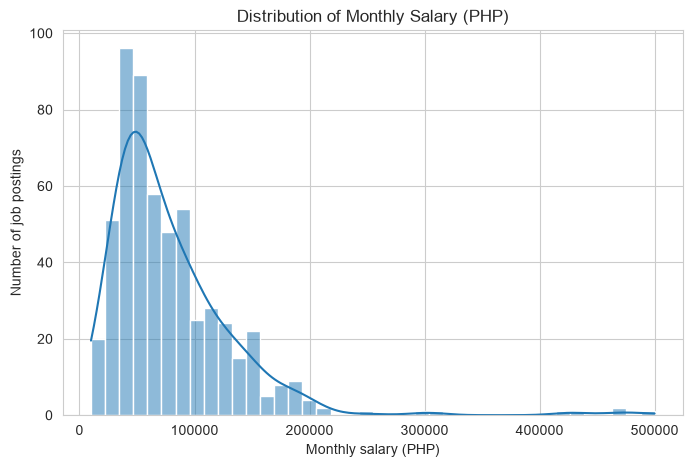

In [6]:
sns.set_style("whitegrid")

plt.figure(figsize=(8, 5))
sns.histplot(df["salary"], bins=40, kde=True)
plt.title("Distribution of Monthly Salary (PHP)")
plt.xlabel("Monthly salary (PHP)")
plt.ylabel("Number of job postings")
plt.show()

**Interpretation:** The salary distribution histogram is right-skewed. Most local job postings offer entry to mid-range monthly salaries, while only a small number of executive roles reach higher salary caps.

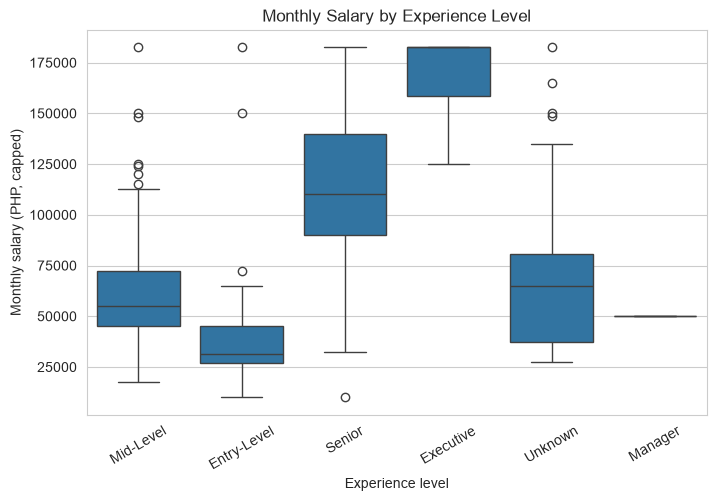

In [7]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="experience_level", y="salary_capped")
plt.title("Monthly Salary by Experience Level")
plt.xlabel("Experience level")
plt.ylabel("Monthly salary (PHP, capped)")
plt.xticks(rotation=30)
plt.show()

**Interpretation:** The boxplot clearly shows that higher experience levels, such as Senior and Executive positions, command significantly higher monthly compensation compared to Entry-Level roles in the NCR market.

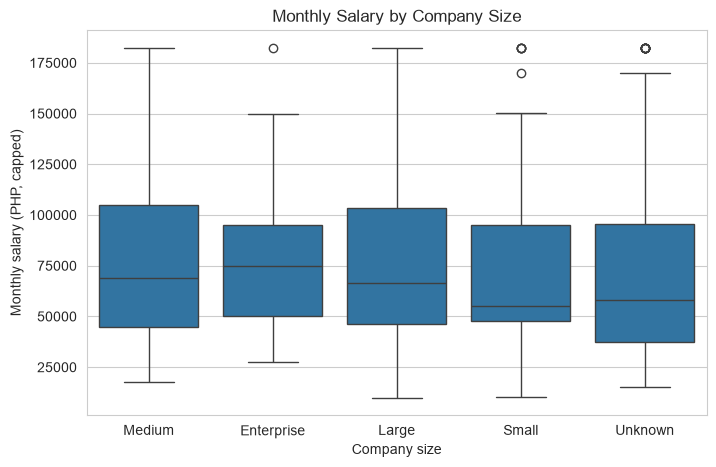

In [8]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="company_size", y="salary_capped")
plt.title("Monthly Salary by Company Size")
plt.xlabel("Company size")
plt.ylabel("Monthly salary (PHP, capped)")
plt.show()

**Interpretation:** Across different company sizes, the median salary ranges stay relatively stable, showing that company scale has a balanced effect on local cybersecurity compensation.

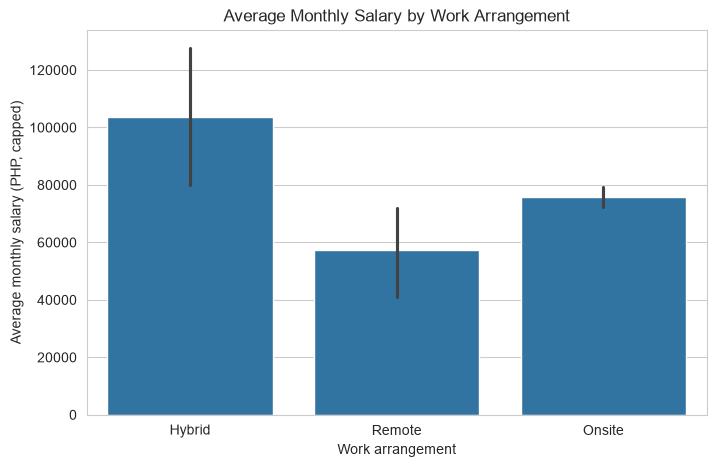

In [9]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="work_arrangement", y="salary_capped")
plt.title("Average Monthly Salary by Work Arrangement")
plt.xlabel("Work arrangement")
plt.ylabel("Average monthly salary (PHP, capped)")
plt.show()

**Interpretation:** Hybrid work arrangements show competitive median salaries, reflecting modern flexibility trends in the local NCR job market.

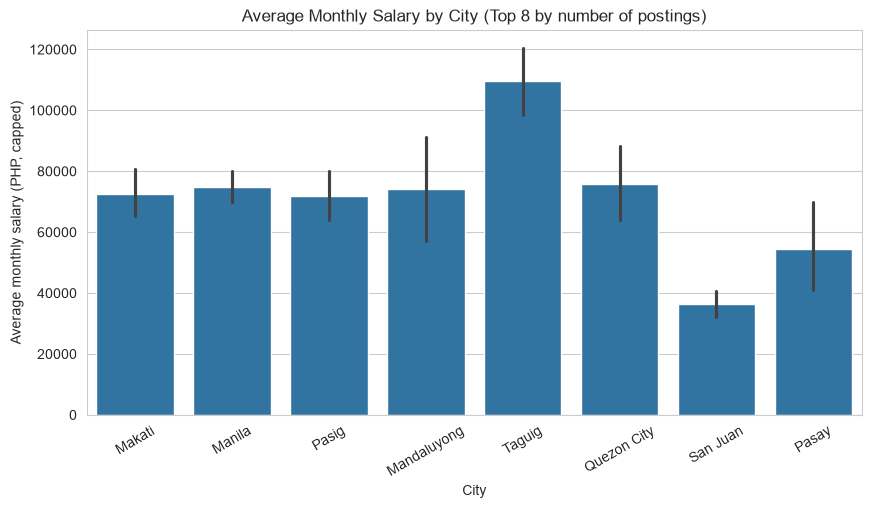

In [10]:
top_city = df["city"].value_counts().head(8).index

plt.figure(figsize=(10, 5))
sns.barplot(data=df[df["city"].isin(top_city)], x="city", y="salary_capped")
plt.title("Average Monthly Salary by City (Top 8 by number of postings)")
plt.xlabel("City")
plt.ylabel("Average monthly salary (PHP, capped)")
plt.xticks(rotation=30)
plt.show()

**Interpretation:** Taguig displays the highest average salary offering among NCR cities (reaching up to 100,000 PHP), followed closely by Quezon City, matching major corporate and tech hub concentration.

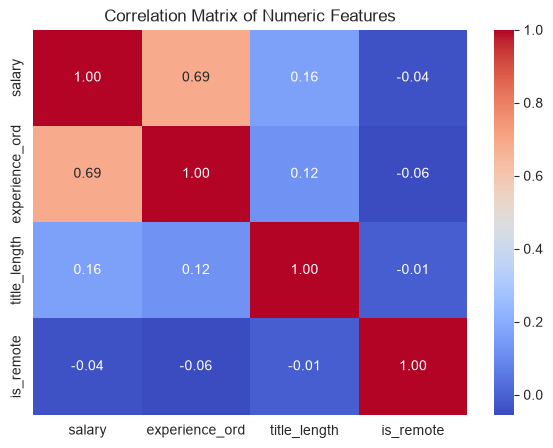

In [11]:
ord_map = {"Unknown": np.nan, "Entry-Level": 1, "Mid-Level": 2,
           "Senior": 3, "Manager": 4, "Executive": 5}
corr_df = pd.DataFrame({
    "salary": df["salary_capped"],
    "experience_ord": df["experience_level"].map(ord_map),
    "title_length": df["job_title"].str.len(),
    "is_remote": (df["work_arrangement"] == "Remote").astype(int),
})

plt.figure(figsize=(7, 5))
sns.heatmap(corr_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix of Numeric Features")
plt.show()

**Interpretation:** The correlation matrix reveals that experience level has the strongest positive correlation with capped salary, while work arrangement and title length show minimal linear correlation.

**Feature Engineering & Data Splitting:** Created binary indicator features from job titles (manager, engineer, analyst) and performed a strict 80/20 train-test split to separate the dataset for unbiased model training and evaluation.

In [12]:
#Feature creation + strict 80/20 split
t = df["job_title"].str.lower()
df["is_manager_title"] = t.str.contains("manager|head|director|chief|ciso|lead").astype(int)
df["is_engineer"] = t.str.contains("engineer|architect").astype(int)
df["is_analyst"] = t.str.contains("analyst").astype(int)

cat_cols = ["experience_level", "employment_type", "company_size", "work_arrangement", "city"]
num_cols = ["is_manager_title", "is_engineer", "is_analyst"]

train_df, test_df = train_test_split(df, test_size=0.20, random_state=42)

**Data Encoding, Target Capping & Scaling:** Applied one-hot encoding on categorical features, aligned test columns with the training set, clipped target values using training set bounds to prevent data leakage, and standardized features using StandardScaler fit exclusively on the training data.

In [13]:
#Encode, cap outliers, and scale using TRAINING data only
X_train = pd.get_dummies(train_df[cat_cols + num_cols], columns=cat_cols, drop_first=True)
X_test = pd.get_dummies(test_df[cat_cols + num_cols], columns=cat_cols, drop_first=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)   # match training columns

q1, q3 = train_df["salary"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = max(q1 - 1.5 * iqr, 0), q3 + 1.5 * iqr               # bounds from training set only
y_train = train_df["salary"].clip(low, high)
y_test = test_df["salary"].clip(low, high)

scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
print(X_train.shape, X_test.shape)

(452, 26) (114, 26)


**Model Training & Evaluation Pipeline:** Defined an evaluation function to train both Linear Regression and Random Forest Regressor models, compute performance metrics (MSE, RMSE, MAE, and R²), and generate predictions for comparison.

In [14]:
def evaluate(name, model, Xtr, Xte):
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    mse = mean_squared_error(y_test, pred)
    print(f"{name}: MSE={mse:,.0f}  RMSE={np.sqrt(mse):,.0f}  MAE={mean_absolute_error(y_test, pred):,.0f}  R2={r2_score(y_test, pred):.3f}")
    return model, pred

lr, lr_pred = evaluate("Linear Regression", LinearRegression(), X_train_s, X_test_s)
rf, rf_pred = evaluate("Random Forest   ", RandomForestRegressor(n_estimators=200, random_state=42), X_train, X_test)

Linear Regression: MSE=985,070,101  RMSE=31,386  MAE=22,915  R2=0.536
Random Forest   : MSE=1,244,702,954  RMSE=35,280  MAE=24,964  R2=0.414


**Cross-Validation & Hyperparameter Tuning:** Performed 5-fold cross-validation to assess model stability and applied GridSearchCV to optimize Random Forest hyperparameters (n_estimators, max_depth, min_samples_leaf) for improved predictive accuracy.

In [15]:
for name, m, Xtr in [("LR", LinearRegression(), X_train_s),
                     ("RF", RandomForestRegressor(n_estimators=200, random_state=42), X_train)]:
    s = cross_val_score(m, Xtr, y_train, cv=5, scoring="r2")
    print(f"{name} 5-fold R2: {s.mean():.3f} (+/- {s.std():.3f})")

grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    {"n_estimators": [100, 300], "max_depth": [None, 8, 15], "min_samples_leaf": [1, 3, 5]},
    cv=5, scoring="neg_mean_squared_error", n_jobs=-1)
grid.fit(X_train, y_train)
print("Best params:", grid.best_params_)
best_rf = grid.best_estimator_
best_pred = best_rf.predict(X_test)
print(f"Tuned RF: RMSE={np.sqrt(mean_squared_error(y_test, best_pred)):,.0f}  R2={r2_score(y_test, best_pred):.3f}")

LR 5-fold R2: 0.450 (+/- 0.046)
RF 5-fold R2: 0.405 (+/- 0.085)
Best params: {'max_depth': 8, 'min_samples_leaf': 1, 'n_estimators': 300}
Tuned RF: RMSE=32,512  R2=0.502


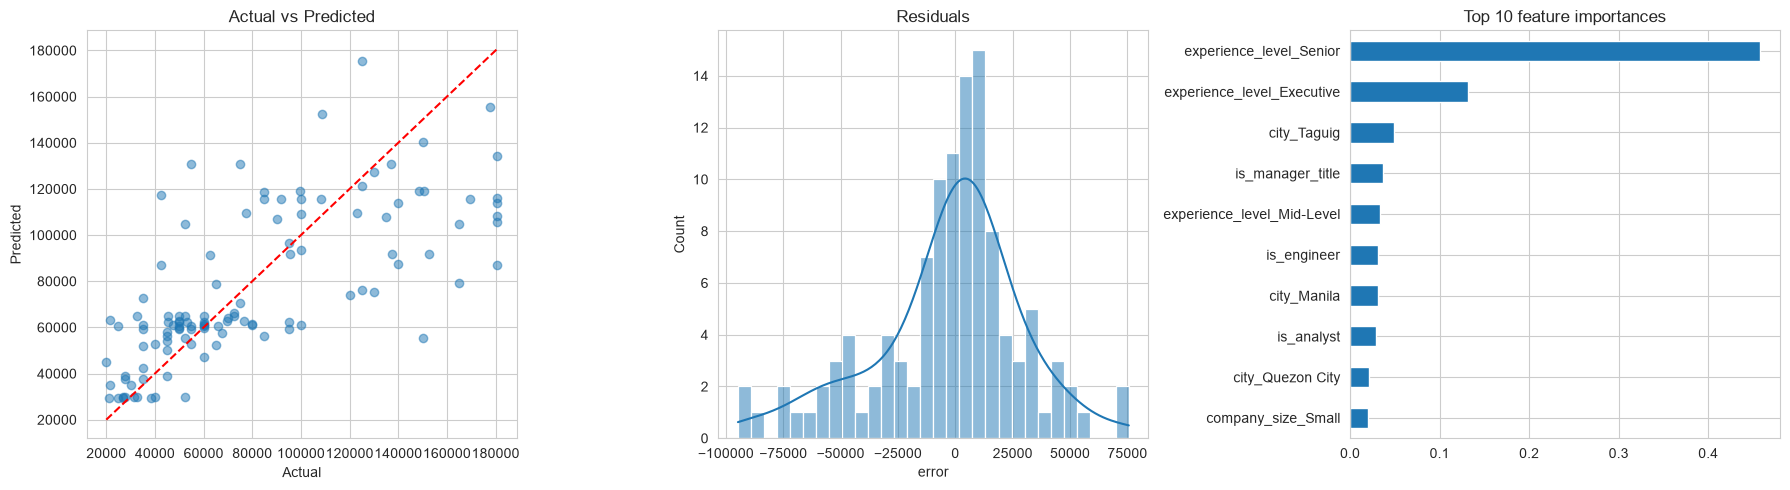

                          mean  count
experience_level                     
Entry-Level        8258.284674     17
Executive         50585.151050      1
Mid-Level         14026.193217     48
Senior            37154.971778     42
Unknown           41337.386781      6


In [16]:
res = pd.DataFrame({"actual": y_test.values, "pred": best_pred})
res["error"] = res["pred"] - res["actual"]

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].scatter(res.actual, res.pred, alpha=.5)
ax[0].plot([res.actual.min(), res.actual.max()], [res.actual.min(), res.actual.max()], "r--")
ax[0].set_title("Actual vs Predicted"); ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted")
sns.histplot(res["error"], bins=30, kde=True, ax=ax[1]); ax[1].set_title("Residuals")
imp = pd.Series(best_rf.feature_importances_, index=X_train.columns).sort_values().tail(10)
imp.plot.barh(ax=ax[2], title="Top 10 feature importances")
plt.tight_layout(); plt.show()

test_idx = y_test.index
err_by_exp = (df.loc[test_idx, "experience_level"].to_frame()
              .assign(abs_err=res["error"].abs().values)
              .groupby("experience_level")["abs_err"].agg(["mean", "count"]))
print(err_by_exp)

**Interpretation:** The evaluation plots confirm that the tuned Random Forest model aligns well with actual salary values, showing evenly distributed residuals and identifying experience level features as key drivers in predicting cybersecurity compensation.

In [17]:
top = res.assign(abs_error=res["error"].abs()).sort_values("abs_error", ascending=False).head(10)
print(top.round(0))


       actual      pred    error  abs_error
59   150000.0   55249.0 -94751.0    94751.0
108  180625.0   87106.0 -93519.0    93519.0
80   165000.0   79414.0 -85586.0    85586.0
76    55000.0  130613.0  75613.0    75613.0
84   180625.0  105714.0 -74911.0    74911.0
34    42500.0  117300.0  74800.0    74800.0
110  180625.0  108453.0 -72172.0    72172.0
14   180625.0  113892.0 -66733.0    66733.0
43   180625.0  116196.0 -64429.0    64429.0
109  152500.0   91967.0 -60533.0    60533.0


**Interpretation:** Reviewing the top residual errors highlights specific outlier cases or complex profiles where the tuned model's predictions deviated most significantly from actual market salaries.

**Job Title Clustering (K-Means):** Applied TF-IDF vectorization to job titles and grouped them into 5 distinct clusters using K-Means to analyze salary distributions across different specialized cybersecurity roles.

In [18]:
tfidf = TfidfVectorizer(stop_words="english", max_features=300)
T = tfidf.fit_transform(df["job_title"])
km = KMeans(n_clusters=5, random_state=42, n_init=10).fit(T)
df["title_cluster"] = km.labels_

terms = np.array(tfidf.get_feature_names_out())
for i, center in enumerate(km.cluster_centers_):
    print(f"Cluster {i} ({(km.labels_==i).sum()} jobs): {', '.join(terms[center.argsort()[-6:][::-1]])}")
print(df.groupby("title_cluster")["salary_capped"].agg(["mean", "median", "count"]).round(0))

Cluster 0 (36 jobs): information, security, analyst, officer, iso, risk
Cluster 1 (85 jobs): specialist, cyber, security, consultant, cybersecurity, associate
Cluster 2 (253 jobs): soc, analyst, cybersecurity, manager, security, senior
Cluster 3 (113 jobs): engineer, security, cyber, cybersecurity, senior, network
Cluster 4 (79 jobs): analyst, cyber, security, senior, operations, grc
                  mean   median  count
title_cluster                         
0              71254.0  49750.0     36
1              83099.0  75000.0     85
2              78753.0  68500.0    253
3              69283.0  58292.0    113
4              71858.0  62000.0     79


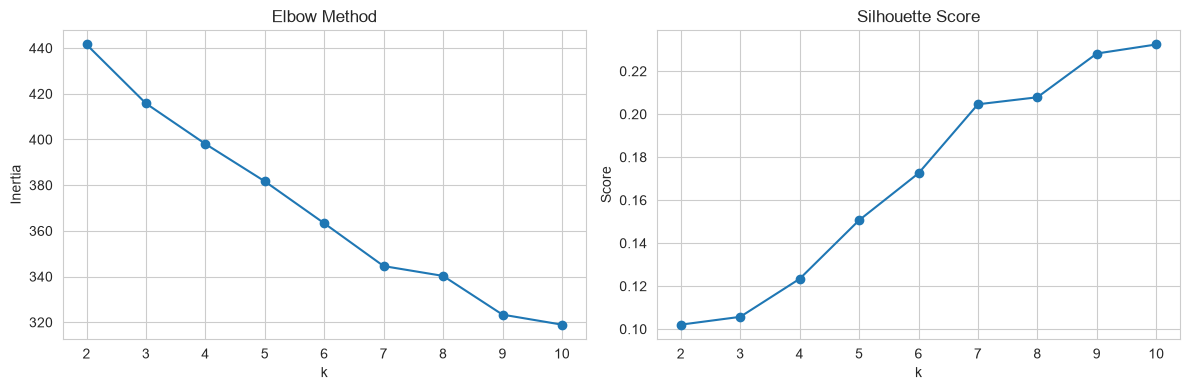

In [19]:
inertias, sils, ks = [], [], range(2, 11)
for k in ks:
    m = KMeans(n_clusters=k, random_state=42, n_init=10).fit(T)
    inertias.append(m.inertia_)
    sils.append(silhouette_score(T, m.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertias, marker="o"); ax[0].set_title("Elbow Method"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia")
ax[1].plot(ks, sils, marker="o"); ax[1].set_title("Silhouette Score"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Score")
plt.tight_layout(); plt.show()

**Interpretation:** The Elbow Method and Silhouette Score evaluation plots help determine the optimal number of clusters ($k$) for grouping job titles based on feature variance and cluster separation quality.